In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

# Load dataset
df = pd.read_excel("/content/zomato_data.xlsx")

print("Original Shape:", df.shape)
print(df.head())

Original Shape: (12079, 33)
   Order ID  Order Amount (INR)  Delivery Time (mins) Order Date  Rating  \
0         1                1930                    32 2023-04-30     4.6   
1         2                 371                    84 2023-01-06     2.7   
2         3                1389                    82 2024-02-18     3.9   
3         4                 329                    50 2023-07-06     1.9   
4         5                 400                    19 2024-06-21     3.4   

   Number of Items  Delivery Distance (km)  Delivery Agent ID Order Status  \
0                9                9.200017                995    Cancelled   
1                1                8.175074                941    Cancelled   
2                5               13.280443                469    Delivered   
3                1               11.892893                329   In-Transit   
4                4                2.570476                172    Cancelled   

  Payment Method  ...  average_cost_for_two pr

In [2]:
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values:
type                 341
address                5
cuisines              75
timings              176
opentable_support      8
dtype: int64


In [3]:
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values:
type                 341
address                5
cuisines              75
timings              176
opentable_support      8
dtype: int64


In [4]:
# Categorical columns
categorical_cols = [
    'type',
    'address',
    'cuisines',
    'timings'
]

for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')

# Numerical column
if 'opentable_support' in df.columns:
    df['opentable_support'] = df['opentable_support'].fillna(
        df['opentable_support'].median()
    )

In [5]:
# Categorical columns
categorical_cols = [
    'type',
    'address',
    'cuisines',
    'timings'
]

for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')

# Numerical column
if 'opentable_support' in df.columns:
    df['opentable_support'] = df['opentable_support'].fillna(
        df['opentable_support'].median()
    )

In [6]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    errors='coerce'
)

df = df.dropna(subset=['Order Date'])

print("Final Shape:", df.shape)

Final Shape: (12079, 33)


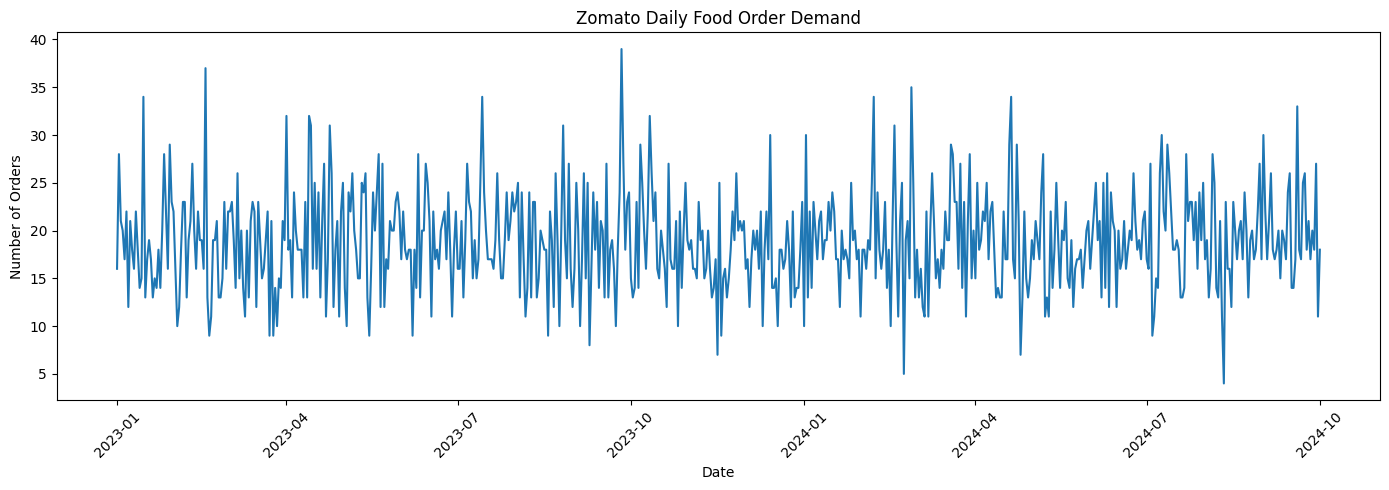

In [8]:
daily = df.groupby('Order Date').size().reset_index(name='demand')
daily = daily.set_index('Order Date')

plt.figure(figsize=(14,5))

plt.plot(
    daily.index,
    daily['demand']
)

plt.title("Zomato Daily Food Order Demand")
plt.xlabel("Date")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
daily['day_of_week'] = daily.index.dayofweek
daily['month'] = daily.index.month
daily['day_of_month'] = daily.index.day

daily['is_weekend'] = (
    daily['day_of_week'] >= 5
).astype(int)

In [10]:
daily['lag_1'] = daily['demand'].shift(1)
daily['lag_7'] = daily['demand'].shift(7)
daily['lag_14'] = daily['demand'].shift(14)
daily['lag_28'] = daily['demand'].shift(28)

In [11]:
daily['rolling_mean_7'] = (
    daily['demand']
    .shift(1)
    .rolling(7)
    .mean()
)

In [12]:
daily['rolling_mean_14'] = (
    daily['demand']
    .shift(1)
    .rolling(14)
    .mean()
)

In [13]:
daily = daily.dropna()

print("Modeling data shape:", daily.shape)

Modeling data shape: (612, 11)


In [14]:
features = [
    'day_of_week',
    'month',
    'day_of_month',
    'is_weekend',
    'lag_1',
    'lag_7',
    'lag_14',
    'lag_28',
    'rolling_mean_7',
    'rolling_mean_14'
]

X = daily[features]

In [15]:
split = int(len(daily) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (489, 10)
Testing data: (123, 10)


In [16]:
#CLASSIFICATION — High vs Low Demand
threshold = daily['demand'].quantile(0.75)

print("High Demand Threshold:", threshold)

High Demand Threshold: 22.0


In [17]:
daily['high_demand'] = (
    daily['demand'] >= threshold
).astype(int)

In [18]:
y_class = daily['high_demand']

y_class_train = y_class.iloc[:split]
y_class_test = y_class.iloc[split:]

In [20]:
#Random Forest Classification
classifier = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

classifier.fit(
    X_train,
    y_class_train
)
class_prediction = classifier.predict(X_test)

class_probability = classifier.predict_proba(
    X_test
)[:, 1]


In [21]:
#classification evaluation
accuracy = accuracy_score(
    y_class_test,
    class_prediction
)

precision = precision_score(
    y_class_test,
    class_prediction,
    zero_division=0
)

recall = recall_score(
    y_class_test,
    class_prediction,
    zero_division=0
)

f1 = f1_score(
    y_class_test,
    class_prediction,
    zero_division=0
)

auc = roc_auc_score(
    y_class_test,
    class_probability
)

print("----- Classification Results -----")
print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1 Score :", round(f1, 3))
print("ROC-AUC  :", round(auc, 3))

----- Classification Results -----
Accuracy : 0.675
Precision: 0.389
Recall   : 0.194
F1 Score : 0.259
ROC-AUC  : 0.566


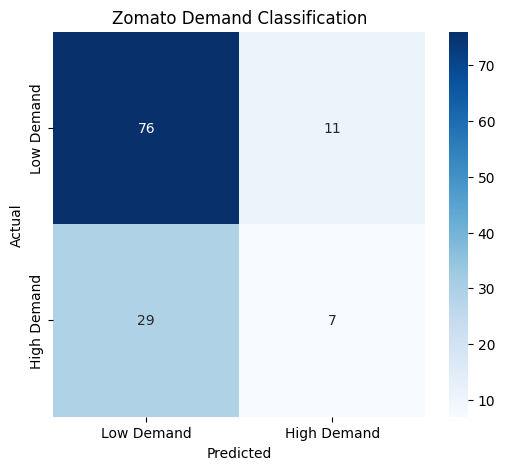

In [22]:
cm = confusion_matrix(
    y_class_test,
    class_prediction
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low Demand', 'High Demand'],
    yticklabels=['Low Demand', 'High Demand']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Zomato Demand Classification")

plt.show()

In [24]:
y_reg = daily['demand']

y_reg_train = y_reg.iloc[:split]
y_reg_test = y_reg.iloc[split:]

In [25]:
regressor = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

regressor.fit(
    X_train,
    y_reg_train
)

RandomForestRegressor(max_depth=12, min_samples_leaf=2, n_estimators=300,
                      n_jobs=-1, random_state=42)

In [26]:
reg_prediction = regressor.predict(X_test)

In [27]:
mae = mean_absolute_error(
    y_reg_test,
    reg_prediction
)

rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        reg_prediction
    )
)

r2 = r2_score(
    y_reg_test,
    reg_prediction
)

print("----- Regression Results -----")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 3))

----- Regression Results -----
MAE : 3.96
RMSE: 5.13
R²  : -0.124


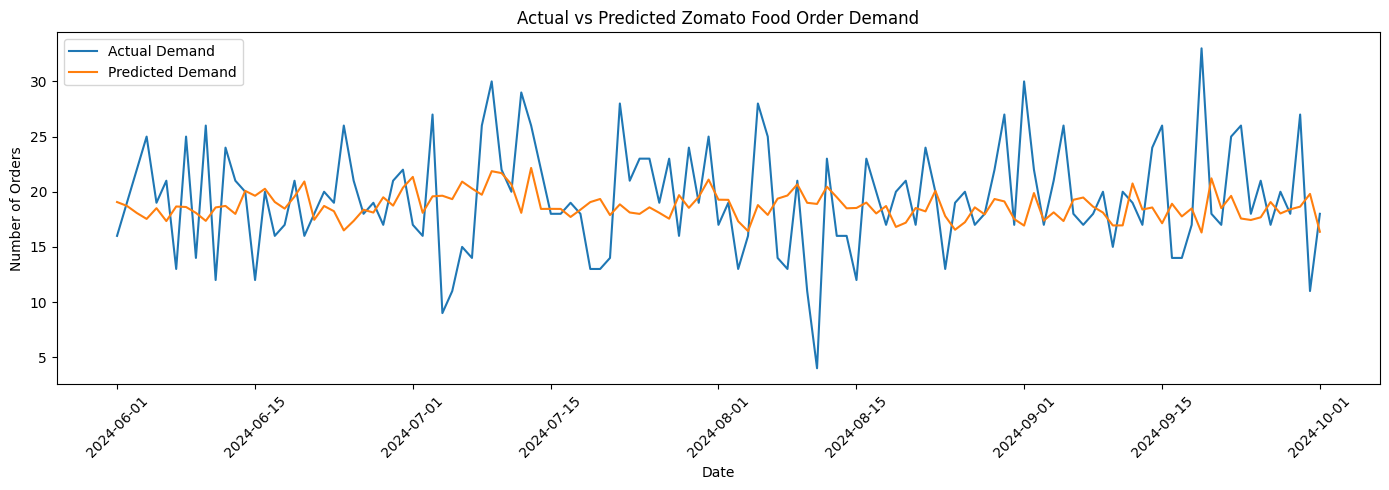

In [28]:
plt.figure(figsize=(14,5))

plt.plot(
    y_reg_test.index,
    y_reg_test.values,
    label='Actual Demand'
)

plt.plot(
    y_reg_test.index,
    reg_prediction,
    label='Predicted Demand'
)

plt.title(
    "Actual vs Predicted Zomato Food Order Demand"
)

plt.xlabel("Date")
plt.ylabel("Number of Orders")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [29]:
importance = pd.DataFrame({
    'Feature': features,
    'Importance': regressor.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

print(importance)

           Feature  Importance
8   rolling_mean_7    0.134977
4            lag_1    0.123676
7           lag_28    0.122219
5            lag_7    0.120009
6           lag_14    0.117076
2     day_of_month    0.116111
9  rolling_mean_14    0.115631
1            month    0.079788
0      day_of_week    0.063831
3       is_weekend    0.006682


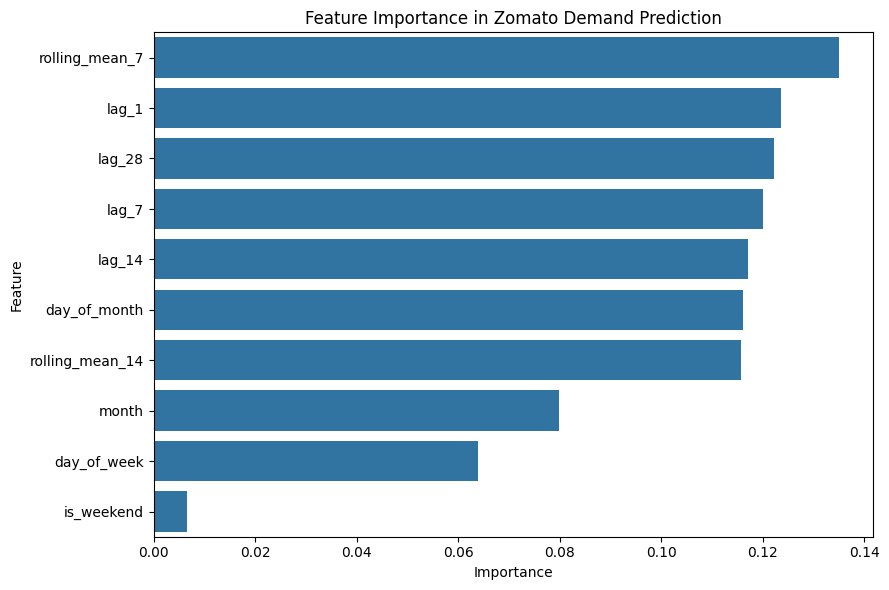

Predicted orders for: 2024-10-02
Expected number of orders: 18
Demand Category: LOW
